## 2. Data Loading and Initial Inspection

In this section, we load the original dataset and examine its basic structure before making any changes. This helps us understand the number of observations and features, identify the target variable, and establish a baseline for later preprocessing decisions.

We preserve the original dataset so that any cleaning or transformation can be performed on a separate copy. This allows us to compare our preprocessing choices and keep the analysis reproducible.

In [2]:
# Import the required libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
import wandb
import sklearn
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize
from sklearn.base import clone
from sklearn.model_selection import learning_curve
import time
import wandb
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from catboost import CatBoostClassifier
import joblib
from pathlib import Path
from datetime import datetime
from sklearn.utils.class_weight import compute_class_weight




In [3]:
# loading the original csv data

# file_path = "/kaggle/input/datasets/janvieremunezero/diabetes-012-health-indicators-brfss2015/diabetes_012_health_indicators_BRFSS2015.csv"
data = pd.read_csv("data/diabetes_012_health_indicators_BRFSS2015.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


In [4]:
data.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [5]:
# checking the dimension of our dataset
print("Number of rows and columns:", data.shape)


Number of rows and columns: (253680, 22)


Interpretation: Each row represents an observation, and each column represents a recorded variable. We inspected 253,680 rows and 22 columns based on our earlier results.

In [6]:
# Identifying the predictors and the target
target = "Diabetes_012"

features = [
    column for column in data.columns
    if column != target
]

print("Target variable:", target)
print("Number of predictor features:", len(features))
print("Predictor names:", features)

Target variable: Diabetes_012
Number of predictor features: 21
Predictor names: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


Interpretation: Diabetes_012 is what we want the model to predict. The other 21 columns are the inputs used to make that prediction.

In [7]:
# Inspecting the datatype
data.dtypes

Diabetes_012            float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object

Interpretation: The output tells us how pandas stores each column. We will later classify the variables according to their actual meaning, rather than treating all float64 columns as continuous features.

In [8]:
data.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

## 3. Data Quality Assessment

Before preparing the dataset for machine learning, we need to assess its quality and identify any issues that could affect model training and evaluation. This includes checking for missing values, examining the target class distribution, investigating duplicate records, and verifying that feature values are consistent with their expected meanings.

The results of these checks will guide our preprocessing decisions. Rather than automatically removing or modifying data, we will investigate potential issues and justify any changes using evidence. This approach helps preserve useful information and makes our analysis reproducible.

In [10]:
# Check for missing values in each column
missing_values = data.isnull().sum()

print("Missing values per column:")
print(missing_values.to_string())

print("\nTotal missing values:", missing_values.sum())

Missing values per column:
Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0

Total missing values: 0


Interpretation: The missing-value check found no missing entries in any of the 22 columns. Therefore, we do not currently need to apply imputation methods, such as replacing missing values with the mean, median, or mode.

However, this result only confirms that pandas did not detect standard missing values. It does not guarantee that every entry is valid, because some datasets may use numeric codes to represent specific responses or special conditions. We will investigate the possible values of each feature in a later step before finalizing our preprocessing decisions.

## 3.2 Target Class Distribution
The target variable, `Diabetes_012`, contains the categories our model will learn to predict. Examining the number and percentage of observations in each category helps us understand the balance of the classification problem.

This is particularly important because a model trained on an imbalanced dataset may perform well on the most common class while performing poorly on less common classes. We will use the results to guide our choice of evaluation metrics and determine whether class-imbalance strategies should be investigated.

In [11]:
# Count observations in each target class
target_counts = data["Diabetes_012"].value_counts().sort_index()

# Calculate the percentage of each class
target_percentages = (
    data["Diabetes_012"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

# Combine counts and percentages into one table
target_distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages.round(2)
})

print(target_distribution)

               Count  Percentage (%)
Diabetes_012                        
0.0           213703           84.24
1.0             4631            1.83
2.0            35346           13.93


The target classes are imbalanced. Class 0 represents 84.24% of the data, Class 1 represents 1.83%, and Class 2 represents 13.93%. Class 1 has very few samples compared with the other classes, which may make it harder for the model to predict correctly. Therefore, we will use evaluation metrics that show how well the model performs on each class, not just its overall accuracy.

### 3.3 Duplicate Records
Duplicate records can affect model training and evaluation. We will count exact duplicate rows to understand how often identical records appear before deciding whether removing them is appropriate.

In [12]:
# Count exact duplicate rows
duplicate_count = data.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)
print("Percentage of dataset:", round(
    duplicate_count / len(data) * 100, 2
), "%")

Number of exact duplicate rows: 23899
Percentage of dataset: 9.42 %


The dataset contains 23,899 exact duplicate rows, representing 9.42% of all records. However, identical rows may belong to different survey respondents with the same answers. Therefore, we will investigate the duplicates before deciding whether removing them is appropriate.

### 3.4 Investigating Duplicate Patterns

Exact duplicate rows have identical feature values and target labels. However, different rows may share the same feature values but have different target labels. We will check for these conflicting patterns before deciding how to handle duplicates.

In [13]:
# Count each target class within every predictor pattern
pattern_labels = (
    data.groupby(features + ["Diabetes_012"], dropna=False)
    .size()
    .unstack(fill_value=0)
)

# Keep patterns that have more than one target label
conflicts = pattern_labels[
    (pattern_labels > 0).sum(axis=1) > 1
]

# Select all records belonging to those conflicting patterns
indexed_data = data.set_index(features)
conflicting_rows = indexed_data[
    indexed_data.index.isin(conflicts.index)
].reset_index()

# Count records from each target class
conflict_class_counts = (
    conflicting_rows["Diabetes_012"]
    .value_counts()
    .sort_index()
)

conflict_class_percentages = (
    conflicting_rows["Diabetes_012"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

conflict_summary = pd.DataFrame({
    "Count": conflict_class_counts,
    "Percentage (%)": conflict_class_percentages.round(2)
})

print("Conflicting predictor patterns:", len(conflicts))
print("Rows in conflicting patterns:", len(conflicting_rows))
print("\nTarget class distribution:")
print(conflict_summary)

Conflicting predictor patterns: 1834
Rows in conflicting patterns: 6120

Target class distribution:
              Count  Percentage (%)
Diabetes_012                       
0.0            4096           66.93
1.0             338            5.52
2.0            1686           27.55


## Investigating the Number of Conflicting Classes

We will examine whether each conflicting predictor pattern is associated with two or three target classes. This helps us understand the extent of disagreement in the recorded labels before deciding how to handle these patterns.

In [14]:
# Count the number of target classes in each conflicting pattern
classes_per_pattern = (conflicts > 0).sum(axis=1)

# Summarize patterns by the number of classes
pattern_summary = classes_per_pattern.value_counts().sort_index()

print("Number of conflicting patterns by class count:")
print(pattern_summary.to_string())

Number of conflicting patterns by class count:
2    1795
3      39


Out of 1,834 conflicting predictor patterns, 1,795 are associated with two target classes, while 39 are associated with all three classes. This shows that most conflicting patterns involve two different labels. However, these differences do not necessarily mean the records are incorrect, so we will not automatically remove them.

In [15]:
# Count patterns containing each combination of target classes
class_presence = conflicts > 0

class_combinations = (
    class_presence.groupby(
        list(class_presence.columns),
        dropna=False
    )
    .size()
    .sort_values(ascending=False)
)

print("Conflicting patterns by target-class combination:")
print(class_combinations.to_string())

Conflicting patterns by target-class combination:
0.0    1.0    2.0  
True   False  True     1497
       True   False     268
              True       39
False  True   True       30


Most conflicting patterns (1,497) occur between class 0 and class 2. Another 268 patterns involve classes 0 and 1, while 30 involve classes 1 and 2. Only 39 patterns contain all three classes. These findings show that conflicting labels mainly occur between the no-diabetes and diabetes categories. However, we cannot determine the cause of these differences from the available features alone, so we will preserve the original records until we have justified a preprocessing strategy.

### 3.5 Unique Values and Feature Coding

In this section, we examine the values recorded in each column to understand how the features are represented. This helps us identify unexpected values and distinguish between binary variables, categorical variables, ordinal variables, and numerical measurements.

We will compare the observed values with the dataset documentation before deciding whether any corrections or transformations are needed.

We first count the number of distinct values in each column. This provides an overview of how each variable is represented and helps us identify columns that need closer inspection.


In [16]:
# Count distinct values in each column
unique_counts = data.nunique()

print("Number of unique values per column:")
print(unique_counts.to_string())

Number of unique values per column:
Diabetes_012             3
HighBP                   2
HighChol                 2
CholCheck                2
BMI                     84
Smoker                   2
Stroke                   2
HeartDiseaseorAttack     2
PhysActivity             2
Fruits                   2
Veggies                  2
HvyAlcoholConsump        2
AnyHealthcare            2
NoDocbcCost              2
GenHlth                  5
MentHlth                31
PhysHlth                31
DiffWalk                 2
Sex                      2
Age                     13
Education                6
Income                   8


Next, we inspect the actual values recorded in each feature. This helps us identify unexpected codes and understand which variables need to be checked against the dataset codebook.

In [17]:
# Display the distinct values in each column
for column in data.columns:
    values = sorted(data[column].dropna().unique())
    print(f"{column}: {values}")

Diabetes_012: [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
HighBP: [np.float64(0.0), np.float64(1.0)]
HighChol: [np.float64(0.0), np.float64(1.0)]
CholCheck: [np.float64(0.0), np.float64(1.0)]
BMI: [np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(44.0), np.float64(45.0), np.float64(46.0), np.float64(47.0), np.float64(48.0), np.float64(49.0), np.float64(50.0), np.float64(51.0), np.float64(52.0), np.float64(53.0), np.float64(54.0), np.float64(55.0), np

* Most features contain the expected number of values for binary or ordinal variables. However, BMI contains some unusually high values, including 95, 96, and 98. We will examine their frequencies and distribution before deciding whether they require any special treatment. We will also verify feature coding using the dataset documentation.

### Investigating BMI Values

BMI is a numerical feature, so we will examine its distribution and the frequency of unusually high values. This will help us decide whether further investigation is needed without removing valid observations prematurely.

In [18]:
# Summarize the BMI distribution
print("BMI summary:")
print(
    data["BMI"].describe(
        percentiles=[0.95, 0.99, 0.995, 0.999]
    )
)

# Count BMI values of 50 or higher
high_bmi = data.loc[data["BMI"] >= 50, "BMI"]

print("\nNumber of records with BMI >= 50:", len(high_bmi))
print("\nFrequency of BMI values >= 50:")
print(high_bmi.value_counts().sort_index().to_string())

BMI summary:
count    253680.000000
mean         28.382364
std           6.608694
min          12.000000
95%          40.000000
99%          50.000000
99.5%        55.000000
99.9%        81.000000
max          98.000000
Name: BMI, dtype: float64

Number of records with BMI >= 50: 2547

Frequency of BMI values >= 50:
BMI
50.0    372
51.0    253
52.0    215
53.0    237
54.0    113
55.0    169
56.0    109
57.0     86
58.0     71
59.0     54
60.0     63
61.0     35
62.0     43
63.0     34
64.0     24
65.0     19
66.0     13
67.0     15
68.0     14
69.0      9
70.0     15
71.0     49
72.0     14
73.0     47
74.0     16
75.0     52
76.0      3
77.0     55
78.0      1
79.0     66
80.0      2
81.0     49
82.0     37
83.0      2
84.0     44
85.0      1
86.0      1
87.0     61
88.0      2
89.0     28
90.0      1
91.0      1
92.0     32
95.0     12
96.0      1
98.0      7


The BMI values range from 12 to 98, with a mean of 28.38. The 99th percentile is 50, and 2,547 records have BMI values of 50 or higher. These values are uncommon and deserve further investigation, but they are not automatically errors. We will check their validity and distribution before deciding whether any treatment is necessary.

### Visual Inspection of BMI

We will use a boxplot to examine the BMI distribution and identify values that may be statistical outliers. These values will be investigated rather than automatically removed, because an unusual measurement may still be valid.

/tmp/ipykernel_2178198/1063060397.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(data["BMI"], vert=False)


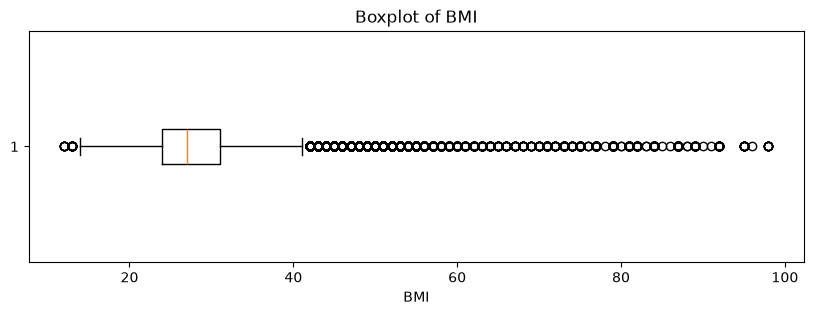

In [19]:
plt.figure(figsize=(10, 3))
plt.boxplot(data["BMI"], vert=False)
plt.title("Boxplot of BMI")
plt.xlabel("BMI")
plt.show()

The boxplot shows a right-skewed BMI distribution, with many potential outliers above the upper whisker and a few below the lower whisker. These values may represent genuine observations rather than errors. Therefore, we will retain the original BMI values for now and investigate them further before deciding whether any treatment is necessary.

### Codebook Verification

We will compare the observed feature values with the documented meanings of the survey variables. This helps us distinguish valid categories and measurements from special codes that may require attention. We will consider the processing applied to the Kaggle dataset before deciding whether any values need to be changed.

In [20]:
# Group features by their likely meanings
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost",
    "DiffWalk", "Sex"
]

ordinal_features = [
    "GenHlth", "Age", "Education", "Income"
]

day_count_features = ["MentHlth", "PhysHlth"]
numerical_features = ["BMI"]

print("Binary features:", len(binary_features))
print("Ordinal features:", len(ordinal_features))
print("Day-count features:", len(day_count_features))
print("Numerical features:", len(numerical_features))

Binary features: 14
Ordinal features: 4
Day-count features: 2
Numerical features: 1


The feature categories were initially identified by examining the observed values in the dataset. The meanings and coding of the variables will be verified using the official CDC 2015 BRFSS Codebook, while considering that the Kaggle dataset is a processed version of the original survey data.

We will examine the documented meanings of selected features and compare them with the values observed in our dataset. This helps us understand what each variable represents and identify any coding issues before preprocessing.

In [21]:
features_to_check = [
    "Age",
    "Education",
    "Income",
    "GenHlth",
    "MentHlth",
    "PhysHlth"
]

for feature in features_to_check:
    print(f"{feature}: {sorted(data[feature].dropna().unique())}")

Age: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0)]
Education: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0)]
Income: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0)]
GenHlth: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
MentHlth: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), 

Feature	Observed values	Meaning
Age	1–13	Age categories, not actual ages in years
Education	1–6	Ordered education levels
Income	1–8	Ordered income categories
GenHlth	1–5	Self-reported general health, from excellent to poor
MentHlth	0–30	Number of days in the past 30 days when mental health was not good
PhysHlth	0–30	Number of days in the past 30 days when physical health was not good

### Data Quality Assessment Summary

The initial assessment found no standard missing values, but the target classes are imbalanced, with the prediabetes class being particularly underrepresented. The dataset also contains exact duplicate records and predictor patterns associated with different target labels. BMI contains some unusually high values that require careful interpretation rather than automatic removal. These findings will guide our preprocessing and evaluation decisions while helping us preserve valid information in the original dataset.

### 3.8 Exploratory Data Analysis (EDA)
Exploratory Data Analysis (EDA) helps us understand the distribution of the target variable, the relationships between features, and patterns that may be relevant to diabetes prediction. We will use visualizations to identify important trends and guide our preprocessing and model development decisions.

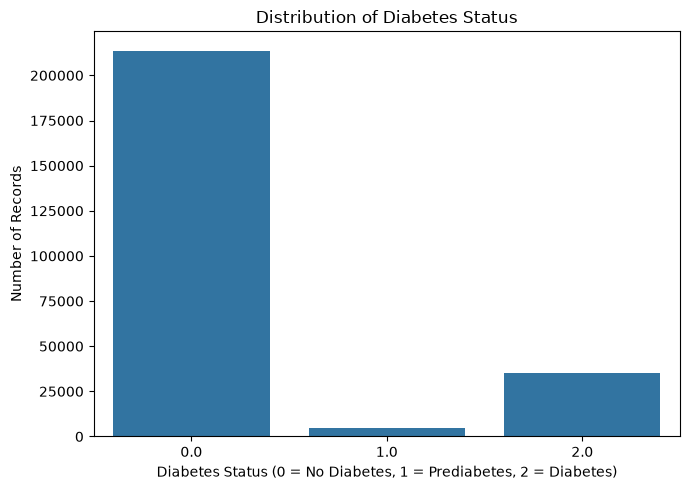

In [22]:
# plot for target class distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=data, x="Diabetes_012")

plt.title("Distribution of Diabetes Status")
plt.xlabel("Diabetes Status (0 = No Diabetes, 1 = Prediabetes, 2 = Diabetes)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

The target distribution shows a strong class imbalance. Most records belong to individuals without diabetes (class 0), followed by individuals with diabetes (class 2). The prediabetes class (class 1) has very few records in comparison. This imbalance may cause a model to favor the majority class and perform poorly when identifying prediabetes. Therefore, we will evaluate performance for each class rather than relying only on overall accuracy.

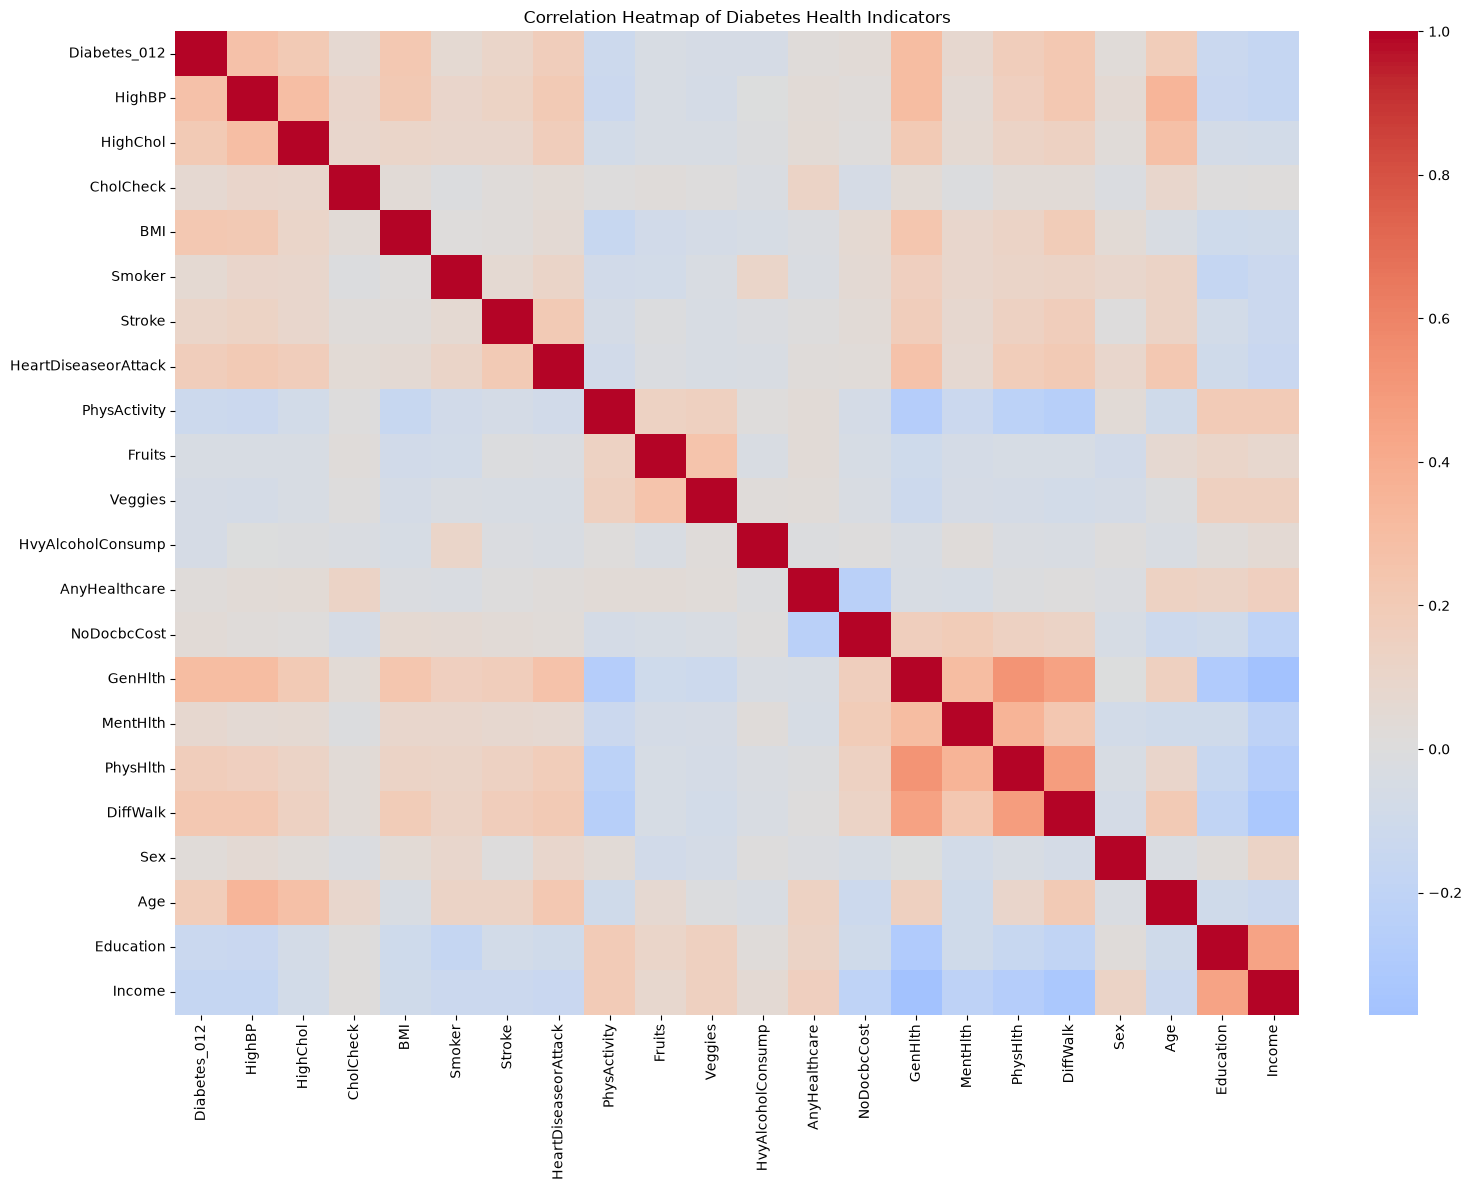

In [23]:
# plot for feature correlation heatmap
correlation_matrix = data.corr(numeric_only=True)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Diabetes Health Indicators")
plt.tight_layout()
plt.show()

The correlation heatmap suggests that diabetes status has positive associations with several health-related features, including high blood pressure, high cholesterol, BMI, age, and general health. Some predictors are also correlated with one another. However, most relationships appear weak to moderate. Since the target contains three categories and several predictors are encoded categorical variables, Pearson correlation provides only an initial view of these relationships and does not establish causation.

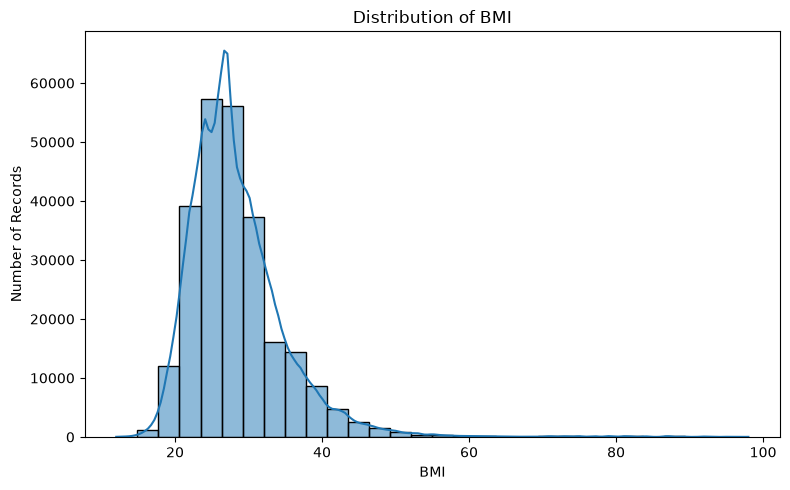

In [24]:
# plot for BMI distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=data, x="BMI", bins=30, kde=True)

plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

The BMI distribution is right-skewed, meaning that most records have lower BMI values while a smaller number have much higher values. Most observations fall approximately between 20 and 40, with the highest concentration around the mid-to-upper 20s. A small number of records have BMI values above 50. These values should be investigated carefully, but they should not automatically be removed because high values may be genuine.

We'll compare diabetes status across high blood pressure and high cholesterol. Because the target has three classes, a grouped percentage chart can help us compare the class composition more fairly than raw counts alone.

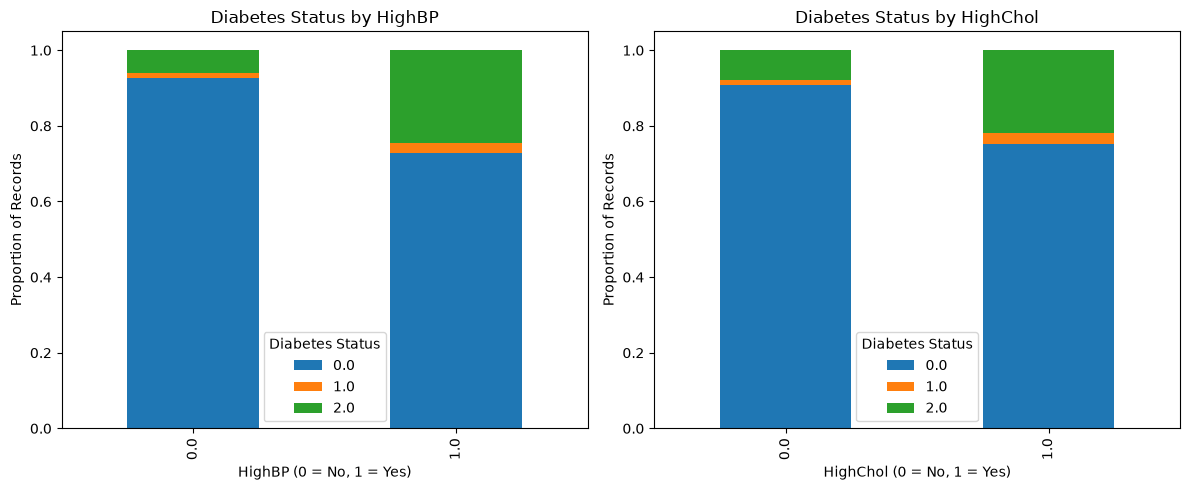

In [26]:
# plot for diabetes status by selected features
selected_features = ["HighBP", "HighChol"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, feature in zip(axes, selected_features):
    proportions = pd.crosstab(
        data[feature],
        data["Diabetes_012"],
        normalize="index"
    )

    proportions.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(f"Diabetes Status by {feature}")
    ax.set_xlabel(f"{feature} (0 = No, 1 = Yes)")
    ax.set_ylabel("Proportion of Records")
    ax.legend(title="Diabetes Status")

plt.tight_layout()
plt.show()

The charts show that the proportion of individuals in the diabetes class (class 2) is higher among those reporting high blood pressure or high cholesterol than among those reporting neither condition. Conversely, the proportion without diabetes (class 0) is lower in these groups. This suggests that high blood pressure and high cholesterol may be useful predictors of diabetes status. However, these visual patterns show associations and do not prove that either condition causes diabetes.

The EDA revealed three important findings: the target variable is strongly imbalanced, BMI is right-skewed with a small number of unusually high values, and diabetes status shows associations with several health-related features. The analysis also suggests that high blood pressure and high cholesterol may help distinguish diabetes status. These findings will guide our preprocessing, model selection, and evaluation strategy. Further analysis will be needed to determine how well the models identify each class.

# Section 4: Data Preprocessing and Feature Preparation
## 4.1 Separate Features and Target
In this section, we prepare the dataset for machine learning. We will first separate the input features from the target variable and split the original data into training, validation, and test sets. We will preserve the original dataset while investigating duplicates, conflicting predictor patterns, and unusual values before deciding how to handle them.

In [27]:
# Separate input features and target variable

X = data.drop(columns=["Diabetes_012"])
y = data["Diabetes_012"]

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Feature dataset shape: (253680, 21)
Target dataset shape: (253680,)


The dataset contains 253,680 records, 21 input features, and one target variable, Diabetes_012. The target is separated from the input features, so the model can learn to predict diabetes status.

## 4.2 Split the Data
We'll use a 70% training, 15% validation, and 15% test split. Stratification helps preserve the proportions of the three target classes in each set.

In [28]:
# First, separate 15% for the test set
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Then take 15% of the original dataset for validation
# 15 / 85 gives the required validation fraction of the remaining data
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (177576, 21) (177576,)
Validation set: (38052, 21) (38052,)
Test set: (38052, 21) (38052,)


The training set contains 177,576 records (70%), while the validation and test sets each contain 38,052 records (15%). This gives us separate data for model training, model selection, and final evaluation.

In [30]:
split_distribution = pd.DataFrame({
    "Original (%)": y.value_counts(normalize=True).sort_index() * 100,
    "Training (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Validation (%)": y_val.value_counts(normalize=True).sort_index() * 100,
    "Test (%)": y_test.value_counts(normalize=True).sort_index() * 100
})

split_distribution.index.name = "Diabetes Status"

print(split_distribution.round(2))

                 Original (%)  Training (%)  Validation (%)  Test (%)
Diabetes Status                                                      
0.0                     84.24         84.24           84.24     84.24
1.0                      1.83          1.83            1.83      1.83
2.0                     13.93         13.93           13.93     13.93


Stratification maintained the original class proportions in all three sets: 84.24% for class 0, 1.83% for class 1, and 13.93% for class 2. However, the prediabetes class remains underrepresented, so we will need to pay special attention to its evaluation metrics.

In [28]:
# Check exact duplicate rows within each split

print("Training exact duplicates:", X_train.join(y_train).duplicated().sum())
print("Validation exact duplicates:", X_val.join(y_val).duplicated().sum())
print("Test exact duplicates:", X_test.join(y_test).duplicated().sum())

Training exact duplicates: 14164
Validation exact duplicates: 1189
Test exact duplicates: 1270


In [31]:
train_records = X_train.copy()
train_records["Diabetes_012"] = y_train

val_records = X_val.copy()
val_records["Diabetes_012"] = y_val

test_records = X_test.copy()
test_records["Diabetes_012"] = y_test

train_keys = set(map(tuple, train_records.to_numpy()))
val_keys = set(map(tuple, val_records.to_numpy()))
test_keys = set(map(tuple, test_records.to_numpy()))

print("Training-validation overlaps:", len(train_keys & val_keys))
print("Training-test overlaps:", len(train_keys & test_keys))
print("Validation-test overlaps:", len(val_keys & test_keys))

Training-validation overlaps: 3473
Training-test overlaps: 3466
Validation-test overlaps: 1316


In [32]:
# Give identical predictor combinations the same group ID
groups = X.groupby(
    X.columns.tolist(),
    dropna=False,
    sort=False
).ngroup()

# First: set aside 15% for testing
splitter_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_idx, test_idx = next(
    splitter_test.split(X, y, groups=groups)
)

# Second: set aside approximately 15% of the full dataset for validation
X_train_val = X.iloc[train_val_idx]
y_train_val = y.iloc[train_val_idx]
groups_train_val = groups.iloc[train_val_idx]

splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=42
)

train_idx, val_idx = next(
    splitter_val.split(
        X_train_val,
        y_train_val,
        groups=groups_train_val
    )
)

# Create the new splits
X_train = X_train_val.iloc[train_idx]
y_train = y_train_val.iloc[train_idx]

X_val = X_train_val.iloc[val_idx]
y_val = y_train_val.iloc[val_idx]

X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (177251, 21) (177251,)
Validation: (38203, 21) (38203,)
Test: (38226, 21) (38226,)


In [33]:
split_distribution = pd.DataFrame({
    "Training (%)": y_train.value_counts(normalize=True) * 100,
    "Validation (%)": y_val.value_counts(normalize=True) * 100,
    "Test (%)": y_test.value_counts(normalize=True) * 100
}).sort_index()

print(split_distribution.round(2))

              Training (%)  Validation (%)  Test (%)
Diabetes_012                                        
0.0                  84.21           84.08     84.55
1.0                   1.82            1.88      1.79
2.0                  13.97           14.04     13.66


In [34]:
train_groups = set(groups.loc[X_train.index])
val_groups = set(groups.loc[X_val.index])
test_groups = set(groups.loc[X_test.index])

print("Train-validation overlap:", len(train_groups & val_groups))
print("Train-test overlap:", len(train_groups & test_groups))
print("Validation-test overlap:", len(val_groups & test_groups))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


Interpratation: To reduce potential data leakage, the dataset was split using groups based on identical predictor combinations. The resulting training, validation, and test sets contained no overlapping predictor groups. The class proportions remained similar across the three sets, although small differences occurred because entire groups were kept together. This approach provides a more cautious evaluation of how well the models generalize to previously unseen predictor combinations.

## Section 4.3 Investigating and Handling Duplicate Records
Before deciding whether to remove duplicate records, we will examine their frequency and determine whether identical records have the same target label. Repeated survey responses do not necessarily represent data errors, so we will preserve the original dataset and evaluate the effect of deduplication separately.

In [35]:
# Count exact duplicate records without modifying the original data

total_rows = len(data)
duplicate_rows = data.duplicated().sum()
unique_rows = len(data.drop_duplicates())

print("Original number of rows:", total_rows)
print("Exact duplicate rows:", duplicate_rows)
print("Unique complete records:", unique_rows)
print("Percentage of duplicate rows:", round(duplicate_rows / total_rows * 100, 2), "%")

Original number of rows: 253680
Exact duplicate rows: 23899
Unique complete records: 229781
Percentage of duplicate rows: 9.42 %


In [36]:
# Create a separate version with exact duplicate rows removed

data_deduplicated = data.drop_duplicates().copy()

print("Original dataset shape:", data.shape)
print("Deduplicated dataset shape:", data_deduplicated.shape)

print(
    "Duplicates remaining:",
    data_deduplicated.duplicated().sum()
)

Original dataset shape: (253680, 22)
Deduplicated dataset shape: (229781, 22)
Duplicates remaining: 0


In [37]:
comparison = pd.DataFrame({
    "Original (%)": (
        data["Diabetes_012"].value_counts(normalize=True) * 100
    ),
    "Deduplicated (%)": (
        data_deduplicated["Diabetes_012"].value_counts(normalize=True) * 100
    )
}).sort_index()

comparison.index.name = "Diabetes Status"

print(comparison.round(2))

                 Original (%)  Deduplicated (%)
Diabetes Status                                
0.0                     84.24             82.71
1.0                      1.83              2.01
2.0                     13.93             15.27


The dataset contains 23,899 exact duplicate rows, representing 9.42% of the original records. Removing these rows reduces the dataset to 229,781 records and changes the target distribution: the proportion of class 0 decreases, while the proportions of classes 1 and 2 increase. Since identical survey responses do not necessarily represent data errors, the original dataset will be retained for the primary analysis, while the deduplicated dataset will be evaluated separately as a sensitivity experiment.

In [38]:
# Count target labels for identical predictor combinations

pattern_label_counts = data.groupby(
    X.columns.tolist(),
    dropna=False
)["Diabetes_012"].nunique()

conflicting_patterns = pattern_label_counts[
    pattern_label_counts > 1
]

print("Conflicting predictor patterns:", len(conflicting_patterns))
print(
    "Number of records belonging to conflicting patterns:",
    data.groupby(X.columns.tolist(), dropna=False)
        .filter(lambda group: group["Diabetes_012"].nunique() > 1)
        .shape[0]
)

Conflicting predictor patterns: 1834
Number of records belonging to conflicting patterns: 6120


The analysis identified 1,834 predictor patterns associated with multiple target labels, involving 6,120 records. This indicates that identical observed predictor values do not always correspond to the same diabetes status. These records may reflect differences not captured by the available features or limitations in the survey data. We will retain them in the primary dataset rather than remove them automatically, since doing so could introduce bias and reduce the diversity of the target classes.

In [39]:
# Examine the highest BMI values and their frequencies

bmi_counts = (
    data["BMI"]
    .value_counts()
    .sort_index()
)

print("BMI values of 50 or higher:")
print(bmi_counts[bmi_counts.index >= 50])

print("\nNumber of records with BMI >= 50:",
      (data["BMI"] >= 50).sum())

print("Number of records with BMI < 15:",
      (data["BMI"] < 15).sum())

BMI values of 50 or higher:
BMI
50.0    372
51.0    253
52.0    215
53.0    237
54.0    113
55.0    169
56.0    109
57.0     86
58.0     71
59.0     54
60.0     63
61.0     35
62.0     43
63.0     34
64.0     24
65.0     19
66.0     13
67.0     15
68.0     14
69.0      9
70.0     15
71.0     49
72.0     14
73.0     47
74.0     16
75.0     52
76.0      3
77.0     55
78.0      1
79.0     66
80.0      2
81.0     49
82.0     37
83.0      2
84.0     44
85.0      1
86.0      1
87.0     61
88.0      2
89.0     28
90.0      1
91.0      1
92.0     32
95.0     12
96.0      1
98.0      7
Name: count, dtype: int64

Number of records with BMI >= 50: 2547
Number of records with BMI < 15: 68


**BMI Outlier Investigation**

The BMI analysis identified 2,547 records with BMI values of 50 or higher and 68 records with BMI values below 15. These values are at the extremes of the observed distribution, but they are not necessarily data-entry errors. Therefore, we will retain them in the primary dataset rather than removing valid observations without sufficient evidence. We will consider appropriate preprocessing methods during model development.

In [40]:
# Separate the input features from the target variable
X = data.drop(columns=["Diabetes_012"])
y = data["Diabetes_012"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Validation target:", y_val.shape)
print("Test target:", y_test.shape)

Training features: (177251, 21)
Validation features: (38203, 21)
Test features: (38226, 21)

Training target: (177251,)
Validation target: (38203,)
Test target: (38226,)


Our dataset has different types of features, so we should not automatically treat every column the same way.
- Binary features: Already encoded as 0 and 1.
- Ordinal features: GenHlth, Age, Education, and Income have ordered categories.
- Day-count features: MentHlth and PhysHlth.
- BMI: A numerical feature.
For a fair comparison, we'll use a ColumnTransformer to apply scaling where appropriate. Scaling is particularly useful for logistic regression and neural networks. Tree-based models such as Random Forest generally do not require it

In [42]:
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost",
    "DiffWalk", "Sex"
]

ordinal_features = ["GenHlth", "Age", "Education", "Income"]

numeric_features = ["BMI", "MentHlth", "PhysHlth"]

# Scale numeric and ordinal features; leave binary features unchanged
preprocessor = ColumnTransformer(
    transformers=[
        ("binary", "passthrough", binary_features),
        ("ordinal", StandardScaler(), ordinal_features),
        ("numeric", StandardScaler(), numeric_features)
    ],
    remainder="drop"
)

In [43]:
# Learn preprocessing parameters from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same parameters to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed validation data:", X_val_processed.shape)
print("Processed test data:", X_test_processed.shape)

Processed training data: (177251, 21)
Processed validation data: (38203, 21)
Processed test data: (38226, 21)


we are scaling the ordinal features while preserving their order, but this treats the gaps between their coded values as approximately equal. That is a practical modeling choice, not a claim that every category has an equal real-world difference.

In [44]:
# Check the processed data for missing or infinite values

for name, X_processed in [
    ("Training", X_train_processed),
    ("Validation", X_val_processed),
    ("Test", X_test_processed)
]:
    print(
        f"{name}: "
        f"NaN values = {np.isnan(X_processed).sum()}, "
        f"Infinite values = {np.isinf(X_processed).sum()}"
    )

Training: NaN values = 0, Infinite values = 0
Validation: NaN values = 0, Infinite values = 0
Test: NaN values = 0, Infinite values = 0


**Preprocessing Results and Data Leakage Prevention**

The preprocessing pipeline was successfully applied to the training, validation, and test sets. The dataset contains 21 input features, and the number of rows in each feature set matches its corresponding target labels. StandardScaler was fitted only on the training data and then applied to the validation and test data using the same learned parameters. Binary features were left unchanged. All three processed datasets contained zero missing and infinite values. This approach helps prevent data leakage and ensures a fairer evaluation of model performance.


In [46]:
# Project configuration
WANDB_PROJECT = "diabetes-health-indicators"
WANDB_MODE = "online"
RANDOM_STATE = 42

# Local folders for results and saved models
RESULTS_DIR = Path("results")
MODELS_DIR = Path("saved_models")

RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

CLASS_NAMES = ["No diabetes", "Prediabetes", "Diabetes"]
CLASS_LABELS = [0, 1, 2]

# Reproducibility
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("W&B:", wandb.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
# print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("W&B mode:", WANDB_MODE)
print("Models will be saved in:", MODELS_DIR.resolve())


W&B: 0.30.0
Scikit-learn: 1.9.0
TensorFlow: 2.21.0
W&B mode: online
Models will be saved in: /home/janviere-munezero/Documents/ML/Introduction to ML/diabetes-risk-prediction/saved_models


In [47]:
WANDB_MODE = "offline"

In [48]:
CLASS_NAMES = ["No diabetes", "Prediabetes", "Diabetes"]
CLASS_LABELS = [0, 1, 2]


def evaluate_and_log(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    experiment_name,
    config,
    mode="online",
    log_learning_curve=False
):
    """Train, evaluate, and log one Scikit-Learn experiment."""

    run = wandb.init(
        project=WANDB_PROJECT,
        name=experiment_name,
        mode=mode,
        config=config,
        reinit="finish_previous"
    )

    try:
        start_time = time.time()
        if "sample_weight" in config:
            model.fit(
                X_train,
                y_train,
                sample_weight=config["sample_weight"]
            )
        else:
            model.fit(X_train, y_train)
        training_seconds = time.time() - start_time

        predictions = model.predict(X_val)

        # Core metrics
        metrics = {
            "validation/accuracy": accuracy_score(y_val, predictions),
            "validation/macro_f1": f1_score(
                y_val, predictions, average="macro", zero_division=0
            ),
            "validation/weighted_f1": f1_score(
                y_val, predictions, average="weighted", zero_division=0
            ),
            "validation/macro_precision": precision_score(
                y_val, predictions, average="macro", zero_division=0
            ),
            "validation/macro_recall": recall_score(
                y_val, predictions, average="macro", zero_division=0
            ),
            # "training/seconds": training_seconds
        }

        report = classification_report(
            y_val,
            predictions,
            labels=CLASS_LABELS,
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0
        )

        for class_id, class_name in zip(CLASS_LABELS, CLASS_NAMES):
            metrics[f"validation/{class_name}/precision"] = (
                report[class_name]["precision"]
            )
            metrics[f"validation/{class_name}/recall"] = (
                report[class_name]["recall"]
            )
            metrics[f"validation/{class_name}/f1"] = (
                report[class_name]["f1-score"]
            )

        # Confusion matrix
        cm = confusion_matrix(y_val, predictions, labels=CLASS_LABELS)
        fig, ax = plt.subplots(figsize=(6, 5))
        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=CLASS_NAMES
        ).plot(ax=ax, values_format="d", cmap="Blues", colorbar=False)
        ax.set_title(f"Confusion Matrix — {experiment_name}")
        fig.tight_layout()
        wandb.log({
            **metrics,
            "validation/confusion_matrix": wandb.Image(fig)
        })
        plt.close(fig)

        # ROC-AUC and precision-recall curves require class probabilities.
        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(X_val)
            class_order = list(model.classes_)

            # Align probability columns to class labels 0, 1, 2.
            probabilities = probabilities[
                :, [class_order.index(c) for c in CLASS_LABELS]
            ]
            y_binary = label_binarize(y_val, classes=CLASS_LABELS)



            # One-vs-rest ROC curves
            fig, ax = plt.subplots(figsize=(7, 5))
            for i, name in enumerate(CLASS_NAMES):
                fpr, tpr, _ = roc_curve(y_binary[:, i], probabilities[:, i])
                auc_i = roc_auc_score(y_binary[:, i], probabilities[:, i])
                ax.plot(fpr, tpr, label=f"{name} (AUC={auc_i:.3f})")

            ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
            ax.set(
                xlabel="False Positive Rate",
                ylabel="True Positive Rate",
                title=f"One-vs-Rest ROC — {experiment_name}"
            )
            ax.legend()
            fig.tight_layout()
            wandb.log({"validation/roc_curves": wandb.Image(fig)})
            plt.close(fig)

            # One-vs-rest precision-recall curves
            fig, ax = plt.subplots(figsize=(7, 5))
            for i, name in enumerate(CLASS_NAMES):
                precision, recall, _ = precision_recall_curve(
                    y_binary[:, i], probabilities[:, i]
                )
                ap = average_precision_score(
                    y_binary[:, i], probabilities[:, i]
                )
                metrics[f"validation/{name}/average_precision"] = ap
                ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

            ax.set(
                xlabel="Recall",
                ylabel="Precision",
                title=f"Precision–Recall Curves — {experiment_name}"
            )
            ax.legend()
            fig.tight_layout()
            wandb.log({"validation/precision_recall_curves": wandb.Image(fig)})
            plt.close(fig)

        # Optional learning curve for traditional ML.
        # This can be computationally expensive, so use it selectively.
        if log_learning_curve:
            sizes, train_scores, val_scores = learning_curve(
                clone(model),
                X_train,
                y_train,
                train_sizes=np.linspace(0.1, 1.0, 5),
                cv=3,
                scoring="f1_macro",
                n_jobs=-1
            )

            fig, ax = plt.subplots(figsize=(7, 5))
            ax.plot(
                sizes, train_scores.mean(axis=1),
                marker="o", label="Training macro F1"
            )
            ax.plot(
                sizes, val_scores.mean(axis=1),
                marker="o", label="Cross-validation macro F1"
            )
            ax.set(
                xlabel="Number of training samples",
                ylabel="Macro F1",
                title=f"Learning Curve — {experiment_name}"
            )
            ax.legend()
            fig.tight_layout()
            wandb.log({"learning_curve": wandb.Image(fig)})
            plt.close(fig)

        # Log metrics after adding AUC and average precision values.
        wandb.log(metrics)

        print(classification_report(
            y_val,
            predictions,
            labels=CLASS_LABELS,
            target_names=CLASS_NAMES,
            zero_division=0
        ))
        print("Logged metrics:", metrics)

        return model, metrics

    finally:
        wandb.finish()

In [49]:
logistic_baseline = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

model_1, metrics_1 = evaluate_and_log(
    model=logistic_baseline,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp01-logistic-regression-baseline",
    config={
        "model": "Logistic Regression",
        "max_iter": 1000,
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)


              precision    recall  f1-score   support

 No diabetes       0.86      0.98      0.91     32121
 Prediabetes       0.00      0.00      0.00       719
    Diabetes       0.53      0.18      0.27      5363

    accuracy                           0.85     38203
   macro avg       0.46      0.38      0.39     38203
weighted avg       0.80      0.85      0.81     38203

Logged metrics: {'validation/accuracy': 0.8453524592309505, 'validation/macro_f1': 0.3936333122896094, 'validation/weighted_f1': 0.806563191620433, 'validation/macro_precision': 0.46284053892943006, 'validation/macro_recall': 0.3845341108706153, 'validation/No diabetes/precision': 0.8611584327086882, 'validation/No diabetes/recall': 0.9757168207714579, 'validation/No diabetes/f1': 0.9148653579508137, 'validation/Prediabetes/precision': 0.0, 'validation/Prediabetes/recall': 0.0, 'validation/Prediabetes/f1': 0.0, 'validation/Diabetes/precision': 0.527363184079602, 'validation/Diabetes/recall': 0.17788551184038784,

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


Interpretation: The baseline Logistic Regression model achieved 84.54% validation accuracy and a macro F1-score of 0.394. However, its performance varied considerably across the three classes. It performed well in identifying individuals without diabetes, achieving a recall of 97.57%, but failed to correctly identify any individuals in the Prediabetes class. Its recall for the Diabetes class was also low at 17.79%.

These results show that accuracy alone is insufficient for evaluating this imbalanced multiclass classification problem. The model's poor performance on minority classes motivates testing class-weighted learning and alternative algorithms in subsequent experiments.

In [50]:
logistic_weighted = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

model_2, metrics_2 = evaluate_and_log(
    model=logistic_weighted,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp02-logistic-regression-balanced",
    config={
        "model": "Logistic Regression",
        "class_weight": "balanced",
        "max_iter": 1000,
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)

              precision    recall  f1-score   support

 No diabetes       0.95      0.67      0.78     32121
 Prediabetes       0.03      0.29      0.05       719
    Diabetes       0.36      0.59      0.45      5363

    accuracy                           0.65     38203
   macro avg       0.45      0.51      0.43     38203
weighted avg       0.85      0.65      0.72     38203

Logged metrics: {'validation/accuracy': 0.6474622411852472, 'validation/macro_f1': 0.42805175102835885, 'validation/weighted_f1': 0.7215052373392782, 'validation/macro_precision': 0.4466244184936016, 'validation/macro_recall': 0.514973646287834, 'validation/No diabetes/precision': 0.9491804006929946, 'validation/No diabetes/recall': 0.6652034494567417, 'validation/No diabetes/f1': 0.7822155513252307, 'validation/Prediabetes/precision': 0.03015873015873016, 'validation/Prediabetes/recall': 0.2906815020862309, 'validation/Prediabetes/f1': 0.054647666361615894, 'validation/Diabetes/precision': 0.36053412462908013, 

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


In [51]:

comparison = pd.DataFrame([
    {"Experiment": "Logistic Regression Baseline", **metrics_1},
    {"Experiment": "Logistic Regression Balanced", **metrics_2}
])

display(
    comparison[
        [
            "Experiment",
            "validation/accuracy",
            "validation/macro_f1",
            "validation/Prediabetes/precision",
            "validation/Prediabetes/recall",
            "validation/Diabetes/recall"
        ]
    ].round(4)
)


,Experiment,validation/accuracy,validation/macro_f1,validation/Prediabetes/precision,validation/Prediabetes/recall,validation/Diabetes/recall
0,Logistic Regression Baseline,0.8454,0.3936,0.0000,0.0000,0.1779
1,Logistic Regression Balanced,0.6475,0.4281,0.0302,0.2907,0.5890


### Experiment 3: Random Forest
Now let's test a different traditional machine learning algorithm.
Random Forest builds multiple decision trees and combines their predictions. Unlike Logistic Regression, it can learn nonlinear relationships and interactions between features.

In [52]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_3, metrics_3 = evaluate_and_log(
    model=random_forest,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp03-random-forest-balanced",
    config={
        "model": "Random Forest",
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 2,
        "class_weight": "balanced",
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)


              precision    recall  f1-score   support

 No diabetes       0.93      0.79      0.85     32121
 Prediabetes       0.03      0.01      0.02       719
    Diabetes       0.35      0.68      0.46      5363

    accuracy                           0.76     38203
   macro avg       0.43      0.49      0.44     38203
weighted avg       0.83      0.76      0.78     38203

Logged metrics: {'validation/accuracy': 0.7583435855822841, 'validation/macro_f1': 0.44279719201340656, 'validation/weighted_f1': 0.7810145163913259, 'validation/macro_precision': 0.433586173935083, 'validation/macro_recall': 0.4934890991676135, 'validation/No diabetes/precision': 0.9269399707174232, 'validation/No diabetes/recall': 0.7883938856199993, 'validation/No diabetes/f1': 0.8520718022913477, 'validation/Prediabetes/precision': 0.02849002849002849, 'validation/Prediabetes/recall': 0.013908205841446454, 'validation/Prediabetes/f1': 0.018691588785046728, 'validation/Diabetes/precision': 0.34532852259779717

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


The class-weighted Random Forest achieved 75.83% validation accuracy and a macro F1-score of 0.4428, the highest macro F1-score among the three experiments so far. It also achieved the highest Diabetes recall of the three models at 0.6782, with a Diabetes F1-score of 0.4576. However, its Prediabetes recall was only 0.0139, substantially lower than that of the class-weighted Logistic Regression model. This indicates that the Random Forest performed better overall according to macro F1 and identified more Diabetes cases, but it struggled to identify Prediabetes cases. Therefore, it cannot yet be considered the best model for every class.

In [53]:
random_forest_tuned = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_4, metrics_4 = evaluate_and_log(
    model=random_forest_tuned,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp04-random-forest-tuned",
    config={
        "model": "Random Forest",
        "n_estimators": 200,
        "max_depth": 20,
        "min_samples_leaf": 5,
        "class_weight": "balanced",
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)

              precision    recall  f1-score   support

 No diabetes       0.94      0.73      0.82     32121
 Prediabetes       0.02      0.04      0.03       719
    Diabetes       0.32      0.73      0.45      5363

    accuracy                           0.71     38203
   macro avg       0.43      0.50      0.43     38203
weighted avg       0.84      0.71      0.75     38203

Logged metrics: {'validation/accuracy': 0.7146035651650394, 'validation/macro_f1': 0.43265388357995943, 'validation/weighted_f1': 0.7527344101157795, 'validation/macro_precision': 0.42890105210328017, 'validation/macro_recall': 0.4995161772316629, 'validation/No diabetes/precision': 0.9397110315128587, 'validation/No diabetes/recall': 0.7269076305220884, 'validation/No diabetes/f1': 0.8197233534615924, 'validation/Prediabetes/precision': 0.023634881825590873, 'validation/Prediabetes/recall': 0.04033379694019471, 'validation/Prediabetes/f1': 0.029804727646454265, 'validation/Diabetes/precision': 0.323357242971390

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


In [54]:

comparison = pd.DataFrame([
    {"Experiment": "Logistic Regression Baseline", **metrics_1},
    {"Experiment": "Logistic Regression Balanced", **metrics_2},
    {"Experiment": "Random Forest Balanced", **metrics_3},
    {"Experiment": "Random Forest Tuned", **metrics_4}

])

display(
    comparison[
        [
    "Experiment",
    "validation/accuracy",
    "validation/macro_f1",
    "validation/weighted_f1",
    "validation/No diabetes/precision",
    "validation/No diabetes/recall",
    "validation/No diabetes/f1",
    "validation/Prediabetes/precision",
    "validation/Prediabetes/recall",
    "validation/Prediabetes/f1",
    "validation/Diabetes/precision",
    "validation/Diabetes/recall",
    "validation/Diabetes/f1"
        ]
    ].round(4)
)


,Experiment,validation/accuracy,validation/macro_f1,validation/weighted_f1,validation/No diabetes/precision,validation/No diabetes/recall,validation/No diabetes/f1,validation/Prediabetes/precision,validation/Prediabetes/recall,validation/Prediabetes/f1,validation/Diabetes/precision,validation/Diabetes/recall,validation/Diabetes/f1
0,Logistic Regression Baseline,0.8454,0.3936,0.8066,0.8612,0.9757,0.9149,0.0000,0.0000,0.0000,0.5274,0.1779,0.2660
1,Logistic Regression Balanced,0.6475,0.4281,0.7215,0.9492,0.6652,0.7822,0.0302,0.2907,0.0546,0.3605,0.5890,0.4473
2,Random Forest Balanced,0.7583,0.4428,0.7810,0.9269,0.7884,0.8521,0.0285,0.0139,0.0187,0.3453,0.6782,0.4576
3,Random Forest Tuned,0.7146,0.4327,0.7527,0.9397,0.7269,0.8197,0.0236,0.0403,0.0298,0.3234,0.7313,0.4484


The tuned Random Forest achieved 71.46% validation accuracy and a macro F1-score of 0.4327. Compared with the original class-weighted Random Forest, its macro F1-score decreased from 0.4428 to 0.4327, indicating that limiting tree depth and increasing the minimum number of samples per leaf did not improve overall class-balanced performance.

The model achieved a Diabetes recall of 0.7313, higher than the 0.6782 obtained by the original Random Forest. However, its Diabetes precision decreased from 0.3453 to 0.3234, and its F1-score decreased slightly from 0.4576 to 0.4484. This suggests that the tuned model identified more Diabetes cases but also produced more false-positive predictions.

Prediabetes performance remained poor. Its recall increased slightly from 0.0139 to 0.0403, but its F1-score was only 0.0298 and its precision was 0.0236. The model also had lower recall for the No diabetes class than the original Random Forest.

Overall, tuning the Random Forest increased Diabetes recall but did not improve macro F1 or the F1-scores for the individual classes. The original class-weighted Random Forest therefore remains the stronger of these two configurations according to macro F1. Further experiments will investigate other traditional machine learning algorithms before selecting the best model.

In [55]:
gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)

model_5, metrics_5 = evaluate_and_log(
    model=gradient_boosting,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp05-gradient-boosting-baseline",
    config={
        "model": "Gradient Boosting",
        "n_estimators": 100,
        "learning_rate": 0.1,
        "max_depth": 3,
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)

              precision    recall  f1-score   support

 No diabetes       0.86      0.98      0.92     32121
 Prediabetes       0.00      0.00      0.00       719
    Diabetes       0.56      0.20      0.29      5363

    accuracy                           0.85     38203
   macro avg       0.47      0.39      0.40     38203
weighted avg       0.80      0.85      0.81     38203

Logged metrics: {'validation/accuracy': 0.8482841661649608, 'validation/macro_f1': 0.402105817094244, 'validation/weighted_f1': 0.8111687045227459, 'validation/macro_precision': 0.47356171083943227, 'validation/macro_recall': 0.39071873616429736, 'validation/No diabetes/precision': 0.8634210816169182, 'validation/No diabetes/recall': 0.9761838049873914, 'validation/No diabetes/f1': 0.9163464207957683, 'validation/Prediabetes/precision': 0.0, 'validation/Prediabetes/recall': 0.0, 'validation/Prediabetes/f1': 0.0, 'validation/Diabetes/precision': 0.5572640509013785, 'validation/Diabetes/recall': 0.1959724035055006

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


Interpratation: The Gradient Boosting baseline achieved 84.83% validation accuracy and a macro F1-score of 0.4021. Although it achieved the highest accuracy among the five experiments so far, its performance was uneven across the three classes.

The model performed well on the No diabetes class, achieving a recall of 97.62% and an F1-score of 0.9163. However, it failed to identify any Prediabetes cases, resulting in a precision, recall, and F1-score of zero for that class. Its Diabetes recall was also low at 19.60%, meaning that it missed most individuals belonging to the Diabetes class.

Compared with the baseline Logistic Regression model, Gradient Boosting achieved slightly higher accuracy (84.83% compared with 84.54%) and a higher macro F1-score (0.4021 compared with 0.3936). It also achieved better Diabetes precision and F1-score. Nevertheless, neither model identified any Prediabetes cases.

Overall, the results demonstrate that Gradient Boosting performs well on the majority class but struggles to identify the minority classes. Its high accuracy is partly influenced by the large proportion of No diabetes records. Therefore, accuracy alone is insufficient for selecting the best model. Further experiments should investigate approaches that improve minority-class performance.

In [56]:
# Give greater weight to records from minority classes
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

gradient_boosting_balanced = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)

model_6, metrics_6 = evaluate_and_log(
    model=gradient_boosting_balanced,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp06-gradient-boosting-balanced",
    config={
        "model": "Gradient Boosting",
        "n_estimators": 100,
        "learning_rate": 0.1,
        "max_depth": 3,
        "class_weighting": "balanced sample weights",
        "sample_weight": sample_weights,
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)

wandb: WARNING Serializing object of type ndarray that is 1418120 bytes


              precision    recall  f1-score   support

 No diabetes       0.96      0.63      0.76     32121
 Prediabetes       0.03      0.34      0.06       719
    Diabetes       0.36      0.62      0.45      5363

    accuracy                           0.62     38203
   macro avg       0.45      0.53      0.42     38203
weighted avg       0.85      0.62      0.70     38203

Logged metrics: {'validation/accuracy': 0.6231971311153575, 'validation/macro_f1': 0.4230194169162629, 'validation/weighted_f1': 0.7035302857655762, 'validation/macro_precision': 0.44791326849916385, 'validation/macro_recall': 0.5291776728576961, 'validation/No diabetes/precision': 0.956470421604268, 'validation/No diabetes/recall': 0.630708882039787, 'validation/No diabetes/f1': 0.7601590934674121, 'validation/Prediabetes/precision': 0.03169469598965071, 'validation/Prediabetes/recall': 0.34075104311543813, 'validation/Prediabetes/f1': 0.0579950289975145, 'validation/Diabetes/precision': 0.35557468790357294, 'v

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


In [57]:
comparison = pd.DataFrame([
    {"Experiment": "Logistic Regression Baseline", **metrics_1},
    {"Experiment": "Logistic Regression Balanced", **metrics_2},
    {"Experiment": "Random Forest Balanced", **metrics_3},
    {"Experiment": "Random Forest Tuned", **metrics_4},
    {"Experiment": "Gradient Boosting Baseline", **metrics_5},
    {"Experiment": "Gradient Boosting Balanced", **metrics_6}



])

display(
    comparison[
        [
    "Experiment",
    "validation/accuracy",
    "validation/macro_f1",
    "validation/weighted_f1",
    "validation/No diabetes/precision",
    "validation/No diabetes/recall",
    "validation/No diabetes/f1",
    "validation/Prediabetes/precision",
    "validation/Prediabetes/recall",
    "validation/Prediabetes/f1",
    "validation/Diabetes/precision",
    "validation/Diabetes/recall",
    "validation/Diabetes/f1"
        ]
    ].round(4)
)


,Experiment,validation/accuracy,validation/macro_f1,validation/weighted_f1,validation/No diabetes/precision,validation/No diabetes/recall,validation/No diabetes/f1,validation/Prediabetes/precision,validation/Prediabetes/recall,validation/Prediabetes/f1,validation/Diabetes/precision,validation/Diabetes/recall,validation/Diabetes/f1
0,Logistic Regression Baseline,0.8454,0.3936,0.8066,0.8612,0.9757,0.9149,0.0000,0.0000,0.0000,0.5274,0.1779,0.2660
1,Logistic Regression Balanced,0.6475,0.4281,0.7215,0.9492,0.6652,0.7822,0.0302,0.2907,0.0546,0.3605,0.5890,0.4473
2,Random Forest Balanced,0.7583,0.4428,0.7810,0.9269,0.7884,0.8521,0.0285,0.0139,0.0187,0.3453,0.6782,0.4576
3,Random Forest Tuned,0.7146,0.4327,0.7527,0.9397,0.7269,0.8197,0.0236,0.0403,0.0298,0.3234,0.7313,0.4484
4,Gradient Boosting Baseline,0.8483,0.4021,0.8112,0.8634,0.9762,0.9163,0.0000,0.0000,0.0000,0.5573,0.1960,0.2900
5,Gradient Boosting Balanced,0.6232,0.4230,0.7035,0.9565,0.6307,0.7602,0.0317,0.3408,0.0580,0.3556,0.6161,0.4509


In this experiment, I applied balanced sample weights to the Gradient Boosting model to give more importance to underrepresented classes during training. The model achieved an accuracy of 62.32% and a macro F1-score of 0.4230. Compared with the baseline Gradient Boosting model, the macro F1-score improved from 0.4021 to 0.4230, while the accuracy decreased from 84.83% to 62.32%.

The most important improvement was in minority-class recall. Prediabetes recall increased from 0% to 34.08%, while Diabetes recall increased from 19.60% to 61.61%. This suggests that sample weighting helped the model identify more cases from these underrepresented classes. However, Prediabetes precision remained very low at 3.17%, meaning that many predictions of Prediabetes were incorrect. The model also identified fewer people in the No diabetes class correctly, with its recall decreasing from 97.62% to 63.07%.

Overall, balanced sample weights improved the model's ability to detect minority classes, but increased false positives and reduced overall accuracy. The results demonstrate the trade-off between identifying more minority-class cases and making reliable predictions. We should compare this model with other approaches using macro F1, class-specific precision and recall, and ROC-AUC before selecting the best model.

In [58]:
catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    random_seed=RANDOM_STATE,
    verbose=100,
    allow_writing_files=False
)

catboost_model, catboost_metrics = evaluate_and_log(
    model=catboost_model,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="Experiment 7 CatBoost Balanced",
    config={
        "model": "CatBoost",
        "iterations": 500,
        "learning_rate": 0.05,
        "depth": 6,
        "loss_function": "MultiClass",
        "class_weighting": "Balanced",
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)

0:	learn: 1.0873853	total: 201ms	remaining: 1m 40s
100:	learn: 0.9287109	total: 4.99s	remaining: 19.7s
200:	learn: 0.9116658	total: 9.43s	remaining: 14s
300:	learn: 0.8956952	total: 14.2s	remaining: 9.37s
400:	learn: 0.8794278	total: 18.6s	remaining: 4.59s
499:	learn: 0.8647535	total: 22.9s	remaining: 0us
              precision    recall  f1-score   support

 No diabetes       0.95      0.65      0.77     32121
 Prediabetes       0.03      0.27      0.05       719
    Diabetes       0.34      0.63      0.44      5363

    accuracy                           0.64     38203
   macro avg       0.44      0.51      0.42     38203
weighted avg       0.85      0.64      0.71     38203

Logged metrics: {'validation/accuracy': 0.6386671203832159, 'validation/macro_f1': 0.4230661947951139, 'validation/weighted_f1': 0.7130287367800683, 'validation/macro_precision': 0.442529328203855, 'validation/macro_recall': 0.5144869741532871, 'validation/No diabetes/precision': 0.9547556898841416, 'validation

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


In this experiment, we used CatBoost, a gradient-boosting algorithm based on decision trees, with balanced class weights to address the imbalance in the diabetes dataset. The model achieved a validation accuracy of 63.87% and a macro F1-score of 0.4231.

The model identified 26.84% of actual Prediabetes cases and 62.60% of actual Diabetes cases. However, the precision for Prediabetes was only 2.93%, meaning that many cases predicted as Prediabetes belonged to another class. The model performed better on the No diabetes class, achieving an F1-score of 0.7728, although its recall of 64.91% shows that it incorrectly classified a substantial number of cases from this majority class.

Compared with the baseline Gradient Boosting model, CatBoost improved minority-class detection considerably: Prediabetes recall increased from 0% to 26.84%, and Diabetes recall increased from 19.60% to 62.60%. However, its macro F1-score of 0.4231 was only slightly higher than the baseline's 0.4021. CatBoost also performed similarly to the balanced Gradient Boosting model, which achieved a macro F1-score of 0.4230.

Overall, CatBoost showed that tree-based boosting can identify more minority-class cases when class imbalance is addressed. Nevertheless, its low Prediabetes precision and F1-score indicate that reliably distinguishing Prediabetes remains difficult. Further experiments and evaluation on the held-out test set are needed before selecting the final model.

In [59]:

catboost_tuned = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=8,
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    random_seed=RANDOM_STATE,
    verbose=100,
    allow_writing_files=False
)

model_8, metrics_8 = evaluate_and_log(
    model=catboost_tuned,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="Experiment 8 CatBoost Depth",
    config={
        "model": "CatBoost",
        "iterations": 500,
        "learning_rate": 0.05,
        "depth": 8,
        "loss_function": "MultiClass",
        "class_weighting": "Balanced",
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)


0:	learn: 1.0866872	total: 75.8ms	remaining: 37.8s


100:	learn: 0.9011724	total: 8.48s	remaining: 33.5s
200:	learn: 0.8620991	total: 16.1s	remaining: 24s
300:	learn: 0.8226813	total: 23.7s	remaining: 15.7s
400:	learn: 0.7821438	total: 31.1s	remaining: 7.68s
499:	learn: 0.7470592	total: 38.5s	remaining: 0us
              precision    recall  f1-score   support

 No diabetes       0.95      0.67      0.79     32121
 Prediabetes       0.03      0.19      0.05       719
    Diabetes       0.34      0.68      0.45      5363

    accuracy                           0.67     38203
   macro avg       0.44      0.51      0.43     38203
weighted avg       0.85      0.67      0.73     38203

Logged metrics: {'validation/accuracy': 0.6659424652514201, 'validation/macro_f1': 0.4295999353124354, 'validation/weighted_f1': 0.727498007947021, 'validation/macro_precision': 0.43845361194410576, 'validation/macro_recall': 0.5130054548052555, 'validation/No diabetes/precision': 0.9504407701416605, 'validation/No diabetes/recall': 0.6746676628996606, 'validat

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


This experiment investigated whether increasing the tree depth of CatBoost from 6 to 8 would improve classification performance.

The model used 500 boosting iterations, a learning rate of 0.05, a tree depth of 8, and balanced class weights. 
In result the model achieved an accuracy of approximately 66.59%, a macro F1 score of 0.4296, and a weighted F1 score of 0.7275. Its recall was 18.64% for prediabetes and 67.80% for diabetes.

Compared with the balanced CatBoost model using a depth of 6, increasing the depth to 8 improved accuracy from 63.87% to 66.59% and slightly improved macro F1 from 0.4231 to 0.4296. Diabetes recall also increased from 62.60% to 67.80%. However, prediabetes recall decreased from 26.84% to 18.64%. This shows that the deeper model improved some aspects of classification but became less effective at identifying prediabetes cases.

Increasing tree depth did not improve every evaluation metric. This result demonstrate why model tuning should consider class-specific performance and macro F1 rather than accuracy alone.

In [60]:
comparison = pd.DataFrame([
    {"Experiment": "Logistic Regression Baseline", **metrics_1},
    {"Experiment": "Logistic Regression Balanced", **metrics_2},
    {"Experiment": "Random Forest Balanced", **metrics_3},
    {"Experiment": "Random Forest Tuned", **metrics_4},
    {"Experiment": "Gradient Boosting Baseline", **metrics_5},
    {"Experiment": "Gradient Boosting Balanced", **metrics_6},
    {"Experiment": "CatBoost Balanced", **catboost_metrics},
    {"Experiment": "CatBoost_Tuned", **metrics_8}
])

display(
    comparison[
        [
    "Experiment",
    "validation/accuracy",
    "validation/macro_f1",
    "validation/weighted_f1",
    "validation/No diabetes/precision",
    "validation/No diabetes/recall",
    "validation/No diabetes/f1",
    "validation/Prediabetes/precision",
    "validation/Prediabetes/recall",
    "validation/Prediabetes/f1",
    "validation/Diabetes/precision",
    "validation/Diabetes/recall",
    "validation/Diabetes/f1"
        ]
    ].round(4)
)


,Experiment,validation/accuracy,validation/macro_f1,validation/weighted_f1,validation/No diabetes/precision,validation/No diabetes/recall,validation/No diabetes/f1,validation/Prediabetes/precision,validation/Prediabetes/recall,validation/Prediabetes/f1,validation/Diabetes/precision,validation/Diabetes/recall,validation/Diabetes/f1
0,Logistic Regression Baseline,0.8454,0.3936,0.8066,0.8612,0.9757,0.9149,0.0000,0.0000,0.0000,0.5274,0.1779,0.2660
1,Logistic Regression Balanced,0.6475,0.4281,0.7215,0.9492,0.6652,0.7822,0.0302,0.2907,0.0546,0.3605,0.5890,0.4473
2,Random Forest Balanced,0.7583,0.4428,0.7810,0.9269,0.7884,0.8521,0.0285,0.0139,0.0187,0.3453,0.6782,0.4576
3,Random Forest Tuned,0.7146,0.4327,0.7527,0.9397,0.7269,0.8197,0.0236,0.0403,0.0298,0.3234,0.7313,0.4484
4,Gradient Boosting Baseline,0.8483,0.4021,0.8112,0.8634,0.9762,0.9163,0.0000,0.0000,0.0000,0.5573,0.1960,0.2900
5,Gradient Boosting Balanced,0.6232,0.4230,0.7035,0.9565,0.6307,0.7602,0.0317,0.3408,0.0580,0.3556,0.6161,0.4509
6,CatBoost Balanced,0.6387,0.4231,0.7130,0.9548,0.6491,0.7728,0.0293,0.2684,0.0528,0.3436,0.6260,0.4436
7,CatBoost_Tuned,0.6659,0.4296,0.7275,0.9504,0.6747,0.7892,0.0293,0.1864,0.0507,0.3356,0.6780,0.4489


In [62]:
# Create the folder 
MODELS_DIR = Path("saved_models")
MODELS_DIR.mkdir(exist_ok=True)

# Save the model and preprocessing pipeline together
model_artifact = {
    "model": random_forest ,
    "preprocessor": preprocessor,
    "model_name": "Random Forest (Balanced)",
    "selection_metric": "Validation Macro F1",
    "validation_macro_f1": 0.442797,
    "random_state": RANDOM_STATE,
    "class_names": CLASS_NAMES
}

model_path = MODELS_DIR / "best_traditional_model.joblib"
joblib.dump(model_artifact, model_path)

print(f"Model saved successfully: {model_path}")
print(f"File size: {model_path.stat().st_size / (1024**2):.2f} MB")

Model saved successfully: saved_models/best_traditional_model.joblib
File size: 581.70 MB


In [63]:
# Load the saved artifact
saved_artifact = joblib.load(
    "saved_models/best_traditional_model.joblib"
)

# Check that both objects were saved
print("Model:", saved_artifact["model_name"])
print("Selection metric:", saved_artifact["selection_metric"])
print("Validation Macro F1:", saved_artifact["validation_macro_f1"])
print("Preprocessor available:", saved_artifact["preprocessor"] is not None)
print("Model type:", type(saved_artifact["model"]).__name__)

Model: Random Forest (Balanced)
Selection metric: Validation Macro F1
Validation Macro F1: 0.442797
Preprocessor available: True
Model type: RandomForestClassifier


## Comparative Analysis and Interpretation of Traditional Machine Learning Experiments

Eight experiments were conducted using Logistic Regression, Random Forest, Gradient Boosting, and CatBoost. The experiments explored the effects of class weighting and hyperparameter tuning on a three-class diabetes-status classification task. Because the dataset is imbalanced, macro F1 was used as the primary metric for model selection, alongside accuracy, weighted F1, and class-specific precision and recall.

### 1. Baseline Models and Class Imbalance

The baseline Logistic Regression and Gradient Boosting models achieved relatively high accuracy scores of 84.54% and 84.83%, respectively. However, both models had zero recall for the prediabetes class. This indicates that they failed to correctly identify prediabetes cases at the selected decision thresholds. Their high accuracy was largely influenced by the majority class, which represents approximately 84% of the dataset.

These results demonstrate why accuracy alone is insufficient for evaluating models on imbalanced datasets. Although the baseline Gradient Boosting model achieved the highest accuracy, its macro F1 score of 0.4021 was lower than that of several other experiments.

### 2. Effect of Class Weighting

Class weighting was introduced to give greater importance to errors involving underrepresented classes during model training. The effect was particularly visible in Logistic Regression: macro F1 increased from 0.3936 to 0.4281, while prediabetes recall increased from 0% to 29.07% and diabetes recall increased from 17.79% to 58.90%.

Similarly, weighted Gradient Boosting achieved 34.08% prediabetes recall, compared with 0% for its baseline version. However, its accuracy decreased from 84.83% to 62.32%. Balanced CatBoost also identified more minority-class cases than the unweighted baseline models.

This trade-off occurs because class weighting changes the relative cost of classification errors. Models become more willing to predict minority classes, which can increase recall but also produce more false-positive predictions. For prediabetes, precision remained low across the experiments, ranging from approximately 2.36% to 3.17% among the models that detected some cases. Therefore, improved recall did not necessarily translate into reliable prediabetes predictions.

### 3. Effect of Algorithm Choice and Hyperparameter Tuning

The algorithms differed in how they learned patterns from the health indicators. Logistic Regression provides a relatively simple linear decision boundary, while Random Forest, Gradient Boosting, and CatBoost use tree-based methods that can learn nonlinear relationships and interactions between features.

The balanced Random Forest achieved the highest macro F1 score of 0.4428. Its diabetes F1 score was 0.4576, and its diabetes recall was 67.82%. These results suggest that its learned decision boundaries provided a comparatively strong balance across the three classes, although its prediabetes recall remained very low at 1.39%.

Tuning the Random Forest by limiting tree depth to 20 and increasing the minimum leaf size to 5 changed the balance between class predictions. Diabetes recall increased from 67.82% to 73.13%, but macro F1 decreased from 0.4428 to 0.4327. This demonstrates that improving performance for one class does not necessarily improve overall performance across all classes.

For CatBoost, increasing tree depth from 6 to 8 improved accuracy from 63.87% to 66.59% and macro F1 from 0.4231 to 0.4296. Diabetes recall increased from 62.60% to 67.80%, while prediabetes recall declined from 26.84% to 18.64%. Thus, the deeper CatBoost model improved some metrics but did not outperform the balanced Random Forest on macro F1.

### 4. Model Selection

The balanced Random Forest was selected as the best traditional model because it achieved the highest validation macro F1 score among the eight experiments. Macro F1 was prioritized because it calculates the F1 score for each class separately and then averages the scores, giving each class equal weight regardless of its frequency.

Although the baseline Gradient Boosting model achieved higher accuracy, it failed to identify prediabetes cases. The balanced Gradient Boosting model achieved the highest prediabetes recall, but its macro F1 was lower than that of the balanced Random Forest. The tuned Random Forest achieved the highest diabetes recall, but its overall macro F1 was also lower.

Therefore, the balanced Random Forest represents the strongest overall result under the selected metric, rather than the best model for every individual class. Its poor prediabetes performance remains an important limitation that must be considered in subsequent evaluation.

### 5. Limitations and Next Steps

All reported results are validation results and should not be interpreted as final estimates of generalization performance. The models will be compared with deep-learning experiments using the same data splits and evaluation metrics. The selected candidates will then be evaluated on the untouched test set.

The low precision and recall for prediabetes indicate that further work may be needed, including examining class-specific prediction thresholds, reviewing the available features, and conducting additional error analysis. Since the dataset contains self-reported survey indicators, the models should be interpreted as predicting reported diabetes-status categories rather than providing clinical diagnoses.

In [71]:
tf.keras.utils.set_random_seed(RANDOM_STATE)

# Convert features and labels to TensorFlow-compatible types
X_train_dl = np.asarray(X_train_processed, dtype=np.float32)
X_val_dl = np.asarray(X_val_processed, dtype=np.float32)

y_train_dl = np.asarray(y_train, dtype=np.int32)
y_val_dl = np.asarray(y_val, dtype=np.int32)

# Set batch size
BATCH_SIZE = 512

# Create the training dataset
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train_dl, y_train_dl))
    .shuffle(
        buffer_size=50000,
        seed=RANDOM_STATE,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(1)
)

# Create the validation dataset
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val_dl, y_val_dl))
    .batch(BATCH_SIZE)
    .prefetch(1)
)

# Calculate class weights to address class imbalance
classes = np.array([0, 1, 2])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_dl
)

class_weight_dict = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Class weights:", class_weight_dict)
print("Training dataset prepared successfully.")

Training batches: 347
Validation batches: 75
Class weights: {0: 0.39584128919588285, 1: 18.309162276624317, 2: 2.38596562075139}
Training dataset prepared successfully.
